# 📊 Distribution Charts: what do my numbers look like?

**Zero Grad · Data Analysis course · Visualization**

This is the solved notebook of the *Distribution* lesson.
The lesson page explains the ideas: when to use each chart and how to read it.
Here we draw every chart on real data, with **Matplotlib**, **Seaborn** and **Plotly**.

**The data:** NileCart, an online shop in Cairo that delivers all over Egypt. Prices are in EGP.
Every row of `sales.csv` is one order line: one product, a quantity, a price, a discount.

**The question of this notebook:** *How much does a typical NileCart order bring in?*
One number won't answer it. We need to see the whole **distribution**.

| # | Chart | Answers |
|---|---|---|
| 1 | Histogram | What is the shape? Where is the center? How wide is the spread? |
| 2 | Bins | Does my histogram tell the truth? |
| 3 | Log scale | What hides behind a long tail? |
| 4 | KDE | A smooth shape, and comparing groups |
| 5 | Box plot | Comparing many groups, spotting outliers |
| 6 | Violin & strip | What a box plot hides |
| 7 | ECDF | What % of orders are below X? |
| 8 | Discrete values | When a histogram is the wrong chart |

---
# 0️⃣ Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "notebook_connected"
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4)
pd.options.display.float_format = "{:,.1f}".format

# On Kaggle the data lives under /kaggle/input, locally in the repo's data/ folder
on_kaggle = sorted(Path("/kaggle/input").glob("**/sales.csv"))
DATA = on_kaggle[0] if on_kaggle else Path("../../data/sales.csv")

sales = pd.read_csv(DATA, parse_dates=["order_date"])
orders = sales[sales["status"] == "completed"].copy()   # money that actually came in
print(sales.shape, "->", orders.shape)
orders.head()

(1466, 18) -> (1074, 18)


,order_id,order_date,customer_id,name,governorate,region,segment,product_id,product_name,category,quantity,unit_price,discount,gross,revenue,unit_cost,profit,status
1,10001,2024-01-01,132,Yasmin Mostafa,Cairo,Greater Cairo,Corporate,101,Laptop,Electronics,9.0,"30,400.0",0.1,"273,600.0","259,920.0",27200,"15,120.0",completed
2,10004,2024-01-02,131,Yasmin Fawzy,Sharqia,Delta,Corporate,111,Notebook,Stationery,10.0,57.0,0.0,570.0,570.0,20,370.0,completed
4,10005,2024-01-02,13,Tarek Saleh,Cairo,Greater Cairo,Consumer,105,Keyboard,Accessories,4.0,"1,140.0",0.0,"4,560.0","4,560.0",600,"2,160.0",completed
5,10006,2024-01-03,101,Amr Mostafa,Gharbia,Delta,Corporate,103,Tablet,Electronics,3.0,"10,450.0",0.0,"31,350.0","31,350.0",9000,"4,350.0",completed
8,10011,2024-01-07,901,Unknown,Unknown,Unknown,Unknown,107,Backpack,Accessories,2.0,855.0,0.1,"1,710.0","1,624.5",420,784.5,completed


We keep the **completed** orders only.
A cancelled or returned order never brought any money, so it doesn't belong in a question about revenue.

---
# 1️⃣ Histogram: the shape of one numeric column

A histogram cuts the range of the numbers into equal **bins** and counts how many values fall in each one.
The height of a bar = how many orders fall in that range.

Start with the two numbers everybody asks for first:

In [2]:
orders["revenue"].agg(["mean", "median", "min", "max"])

mean      18,074.8
median     3,600.0
min           45.6
max      336,000.0
Name: revenue, dtype: float64

The **mean is 5 times the median**. 😮
When that happens, a few very large values are pulling the mean up.
The histogram shows it right away.

## 1.1 Matplotlib

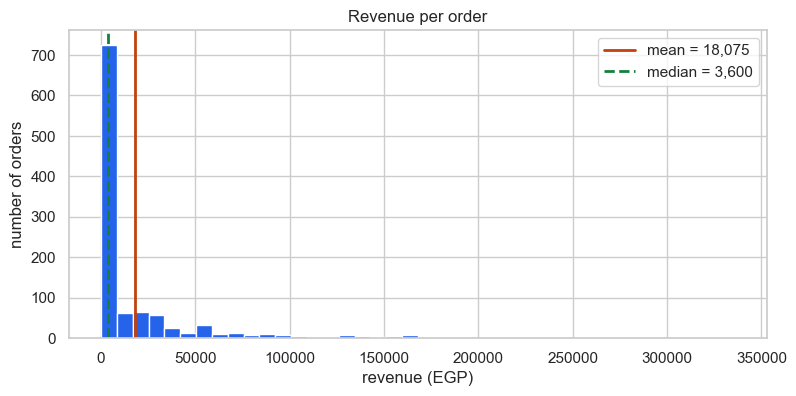

In [3]:
rev = orders["revenue"]

fig, ax = plt.subplots()
ax.hist(rev, bins=40, color="#2563eb", edgecolor="white")
ax.axvline(rev.mean(), color="#c2410c", lw=2, label=f"mean = {rev.mean():,.0f}")
ax.axvline(rev.median(), color="#15803d", lw=2, ls="--", label=f"median = {rev.median():,.0f}")
ax.set(title="Revenue per order", xlabel="revenue (EGP)", ylabel="number of orders")
ax.legend()
plt.show()

## 1.2 Seaborn

Same chart, one line. Seaborn takes the DataFrame and the column name.

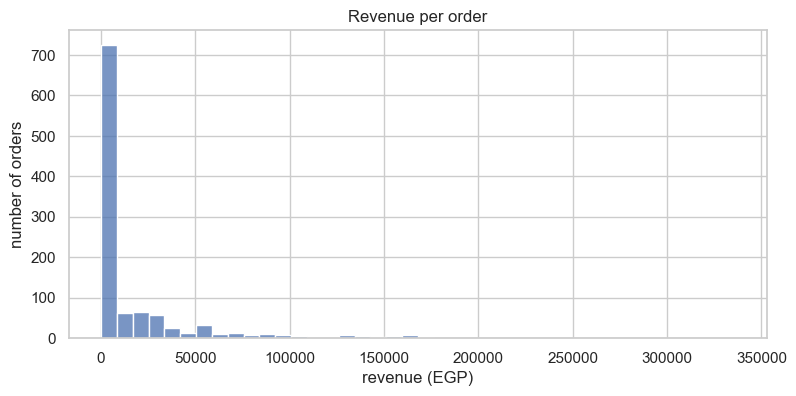

In [4]:
ax = sns.histplot(data=orders, x="revenue", bins=40)
ax.set(title="Revenue per order", xlabel="revenue (EGP)", ylabel="number of orders")
plt.show()

## 1.3 Plotly

Plotly draws the same chart, but **interactive**: hover a bar to see its range and count, drag to zoom.

In [5]:
fig = px.histogram(orders, x="revenue", nbins=40, title="Revenue per order",
                   labels={"revenue": "revenue (EGP)"})
fig.add_vline(x=rev.mean(), line_color="#c2410c", annotation_text="mean")
fig.add_vline(x=rev.median(), line_color="#15803d", line_dash="dash", annotation_text="median")
fig.show()

## 💡 What we read from it

- **Shape:** a tall wall on the left and a long tail to the right. That's a **right-skewed** distribution.
- **Center:** most orders are small. The median (3,600 EGP) describes a typical order far better than the mean.
- **Spread:** from 46 EGP to 336,000 EGP. Almost four orders of magnitude.
- **Outliers?** The far-right orders are not errors. They are laptops bought in bulk by companies.

⚠️ If a manager asks "what's our average order?", answering **18,000 EGP** is technically right and practically misleading.

In [6]:
print("skewness:", round(rev.skew(), 2))   # 0 = symmetric, > 0 = tail on the right

skewness: 3.69


---
# 2️⃣ Bins: the same data, three different stories

The number of bins is a choice, and it changes what you see.

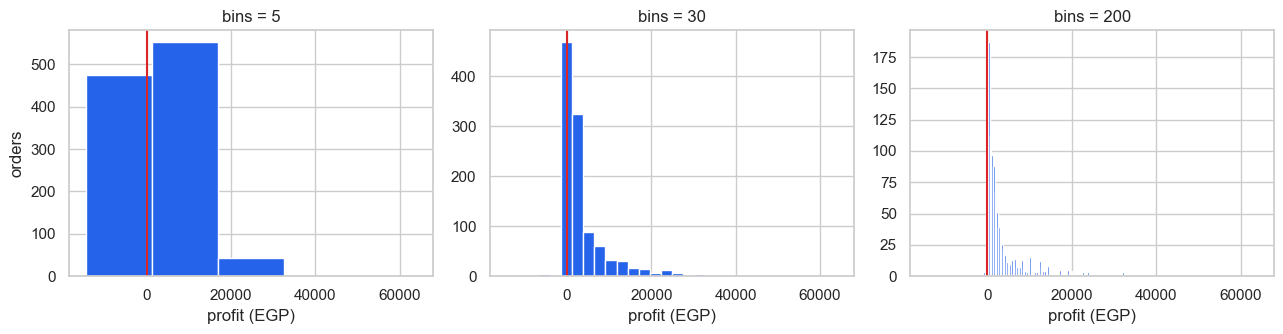

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, b in zip(axes, [5, 30, 200]):
    ax.hist(orders["profit"], bins=b, color="#2563eb", edgecolor="white", lw=.3)
    ax.axvline(0, color="#dc2626", lw=1.5)
    ax.set(title=f"bins = {b}", xlabel="profit (EGP)")
axes[0].set_ylabel("orders")
plt.tight_layout()
plt.show()

- **5 bins:** too coarse. The orders that **lost money** (left of the red line) disappear inside one fat bar.
- **200 bins:** too fine. Noise everywhere, every bar is a handful of orders.
- **30 bins:** the shape is clear, and the losses show up as their own small group.

⚠️ Always try a few bin counts before you trust a histogram.
Seaborn's default (`bins="auto"`) is a good start, not the final answer.

In [8]:
losses = orders[orders["profit"] < 0]
print(f"{len(losses)} orders lost money")
losses.groupby(["category", "discount"]).size()

16 orders lost money


category     discount
Electronics  0.2         16
dtype: int64

The 30-bin histogram pointed us to a real business problem: **every losing order is Electronics with a 20% discount**.
That's the power of a distribution chart: it shows you *where to look next*.

---
# 3️⃣ Log scale: when the numbers span many orders of magnitude

On a normal axis, everything below 20,000 EGP is crushed into the first two bars.
On a **log axis**, every step is ×10 instead of +10,000, so small and large orders both get room.

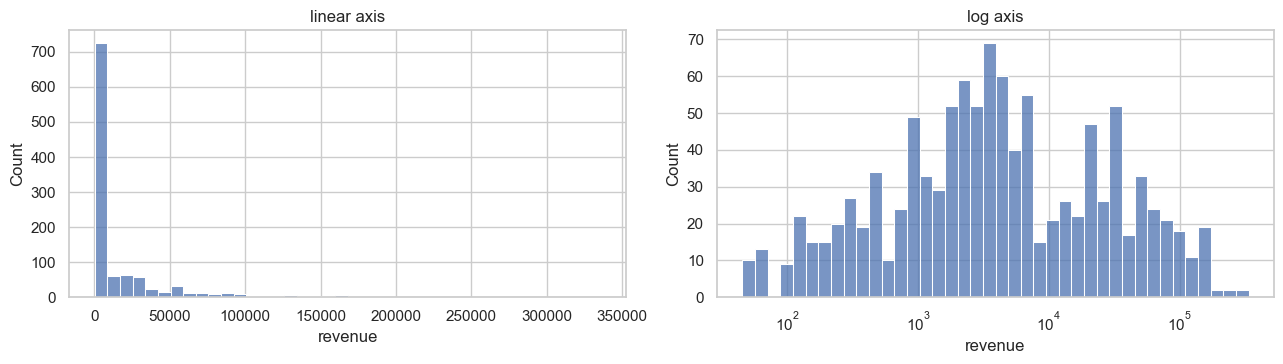

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.histplot(data=orders, x="revenue", bins=40, ax=axes[0])
axes[0].set_title("linear axis")
sns.histplot(data=orders, x="revenue", bins=40, log_scale=True, ax=axes[1])
axes[1].set_title("log axis")
plt.tight_layout()
plt.show()

The log axis shows **several humps** instead of one wall.
Several humps usually mean several groups mixed together. Let's color by category:

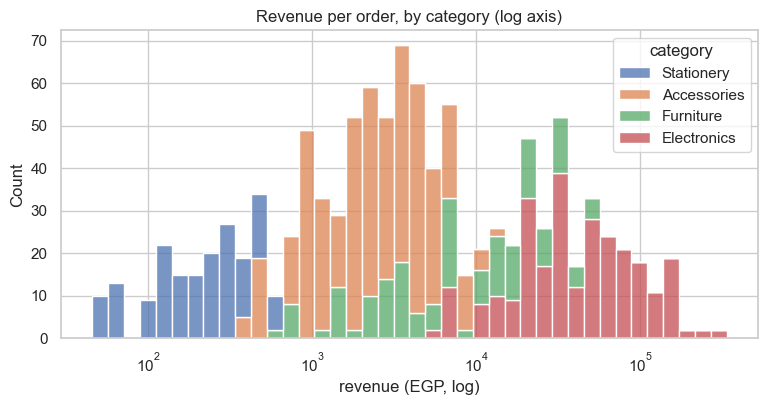

In [10]:
order = ["Stationery", "Accessories", "Furniture", "Electronics"]
ax = sns.histplot(data=orders, x="revenue", hue="category", hue_order=order,
                  log_scale=True, bins=40, multiple="stack")
ax.set(title="Revenue per order, by category (log axis)", xlabel="revenue (EGP, log)")
plt.show()

In [11]:
fig = px.histogram(orders, x="revenue", color="category", log_x=True, nbins=60,
                   category_orders={"category": order}, title="Revenue per order, by category")
fig.show()

## 💡 Insight

Each category lives on its own scale: Stationery orders are in the hundreds, Electronics in the tens of thousands.
"The typical NileCart order" doesn't exist. **There are four kinds of orders.**
So the answer to our question is per category, not one number.

In [12]:
orders.groupby("category")["revenue"].median().sort_values()

category
Stationery       221.7
Accessories    2,360.0
Furniture      6,982.5
Electronics   41,800.0
Name: revenue, dtype: float64

---
# 4️⃣ KDE: a smooth histogram

A **KDE** (Kernel Density Estimate) puts a small bell curve on every value and adds them up.
The result is a smooth line. It's great for **comparing a few groups** on one chart, where stacked bars get messy.

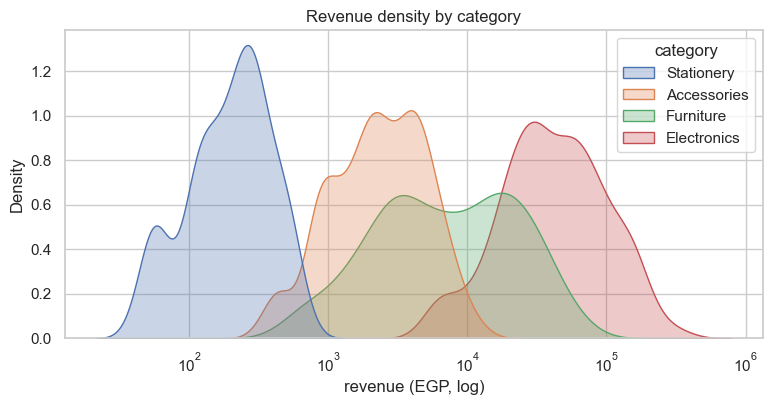

In [13]:
ax = sns.kdeplot(data=orders, x="revenue", hue="category", hue_order=order,
                 log_scale=True, fill=True, common_norm=False, alpha=.3)
ax.set(title="Revenue density by category", xlabel="revenue (EGP, log)")
plt.show()

`common_norm=False` gives every category an area of 1, so a small category isn't flattened by a big one.

The smoothness is controlled by `bw_adjust` (bandwidth), the KDE version of the bins question:

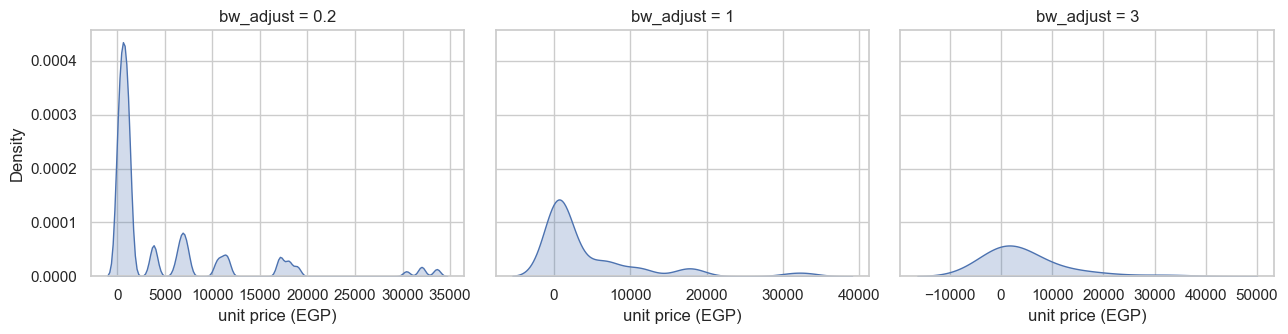

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, bw in zip(axes, [0.2, 1, 3]):
    sns.kdeplot(data=orders, x="unit_price", bw_adjust=bw, fill=True, ax=ax)
    ax.set(title=f"bw_adjust = {bw}", xlabel="unit price (EGP)")
plt.tight_layout()
plt.show()

⚠️ Look at the right panel: the curve goes **below 0 EGP**. No product costs less than zero.
A KDE is an estimate, and it can invent values that can't exist. When the data has a hard limit (prices, ages, counts), check the edges.

---
# 5️⃣ Box plot: five numbers, many groups

A box plot draws the **five-number summary**: min, Q1, median, Q3, max.
Points beyond **1.5 × IQR** from the box are drawn one by one as possible outliers.

In [15]:
q1, q3 = orders["revenue"].quantile([.25, .75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print(f"Q1 = {q1:,.0f}   Q3 = {q3:,.0f}   IQR = {iqr:,.0f}   upper fence = {upper:,.0f}")
print("orders above the fence:", (orders["revenue"] > upper).sum())

Q1 = 1,093   Q3 = 18,900   IQR = 17,807   upper fence = 45,610
orders above the fence: 132


## 5.1 Matplotlib

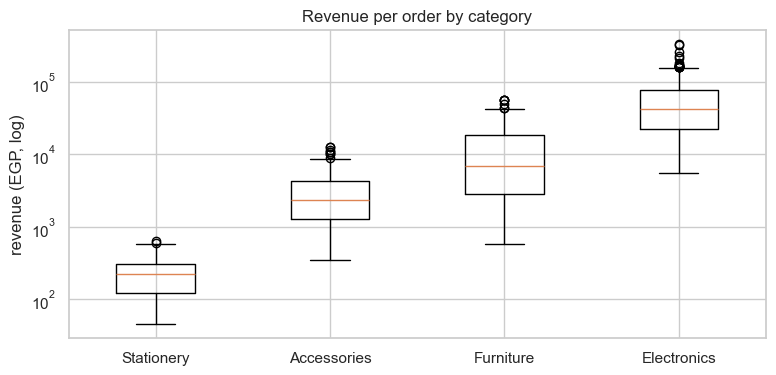

In [16]:
groups = [orders.loc[orders["category"] == c, "revenue"] for c in order]
fig, ax = plt.subplots()
ax.boxplot(groups, tick_labels=order)
ax.set_yscale("log")
ax.set(title="Revenue per order by category", ylabel="revenue (EGP, log)")
plt.show()

## 5.2 Seaborn

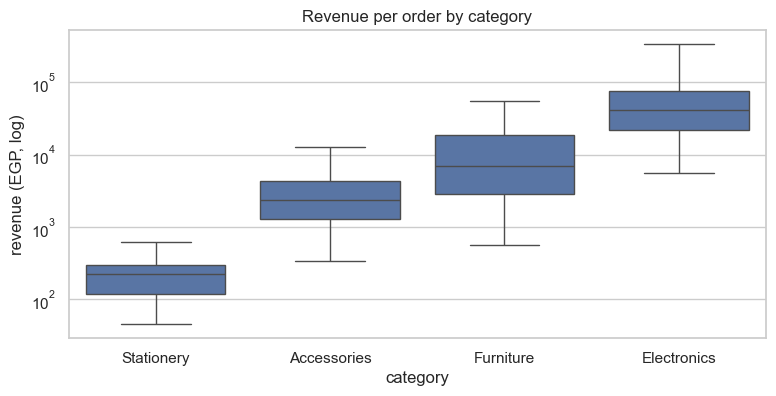

In [17]:
ax = sns.boxplot(data=orders, x="category", y="revenue", order=order, log_scale=True)
ax.set(title="Revenue per order by category", ylabel="revenue (EGP, log)")
plt.show()

## 5.3 Plotly

Hover a box to read its five numbers exactly.

In [18]:
fig = px.box(orders, x="category", y="revenue", log_y=True, category_orders={"category": order},
             points="outliers", title="Revenue per order by category")
fig.show()

## 💡 Insight

- The Stationery and Electronics boxes are worlds apart: the biggest Stationery order is smaller than the smallest Electronics order.
  Accessories and Furniture overlap, so they are closer than the category names suggest.
- The 1.5×IQR rule flags **132** orders on the full data, but only **34** when each category is judged on its own.
  An "outlier" depends on the group you compare it to.
- Box plots are the chart for **comparing many groups side by side**. Ten histograms would be hard to read; ten boxes are easy.

---
# 6️⃣ Violin & strip: what a box plot hides

A box plot shows five numbers only. Two very different shapes can have the same box.
Let's look at **profit** per order, by segment:

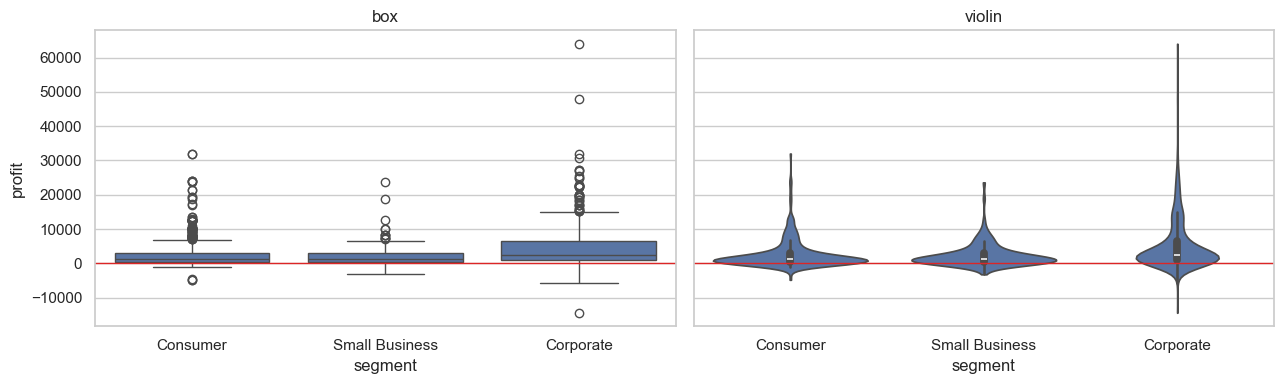

In [19]:
seg = ["Consumer", "Small Business", "Corporate"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
sns.boxplot(data=orders, x="segment", y="profit", order=seg, ax=axes[0])
sns.violinplot(data=orders, x="segment", y="profit", order=seg, cut=0, ax=axes[1])
for ax in axes:
    ax.axhline(0, color="#dc2626", lw=1)
axes[0].set_title("box")
axes[1].set_title("violin")
plt.tight_layout()
plt.show()

A **violin** is a KDE mirrored on both sides, so you see the shape and not only the quartiles.
`cut=0` stops the curve at the real min and max (remember the KDE warning).

With a few hundred points per group, you can also draw **every point**. That's a strip plot:

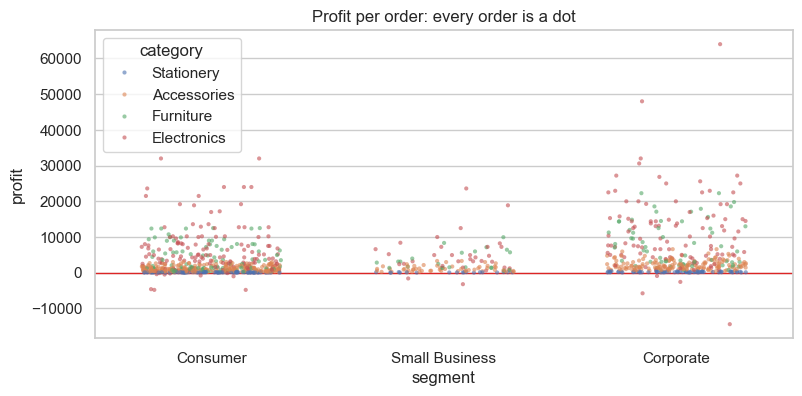

In [20]:
ax = sns.stripplot(data=orders, x="segment", y="profit", order=seg, hue="category", hue_order=order,
                   alpha=.6, size=3, jitter=.3)
ax.axhline(0, color="#dc2626", lw=1)
ax.set(title="Profit per order: every order is a dot")
plt.show()

In [21]:
fig = px.violin(orders, x="segment", y="profit", box=True, points="all", category_orders={"segment": seg},
                title="Profit per order by segment", hover_data=["product_name", "discount"])
fig.show()

## 💡 Insight

The dots below the red line are all Electronics. The strip plot shows it in one glance; the box plot can't.
Corporate customers have the widest spread: their big orders bring the biggest profits **and** the biggest losses.

---
# 7️⃣ ECDF: "what % of orders are below X?"

An **ECDF** (Empirical Cumulative Distribution Function) goes up from 0% to 100%.
At every revenue value on the x axis, the height is the share of orders **at or below** that value.
No bins and no bandwidth to choose.

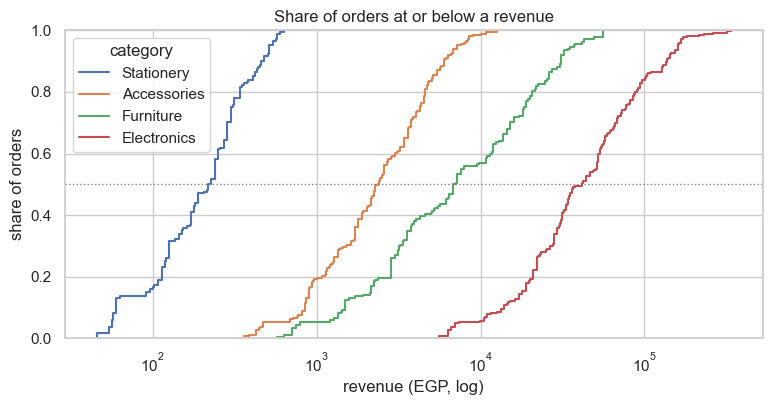

In [22]:
ax = sns.ecdfplot(data=orders, x="revenue", hue="category", hue_order=order, log_scale=True)
ax.axhline(.5, color="gray", ls=":", lw=1)
ax.set(title="Share of orders at or below a revenue", xlabel="revenue (EGP, log)", ylabel="share of orders")
plt.show()

In [23]:
fig = px.ecdf(orders, x="revenue", color="category", log_x=True, category_orders={"category": order},
              title="Share of orders at or below a revenue")
fig.show()

In [24]:
# the same question, answered with pandas
print(f"{(orders['revenue'] <= 5_000).mean():.0%} of all orders are 5,000 EGP or less")

58% of all orders are 5,000 EGP or less


Where a curve crosses the dotted 50% line, that's the group's **median**.
The ECDF is the best chart when the question is about thresholds: "how many orders are under the free-delivery limit?"

---
# 8️⃣ Discrete values: when a histogram is the wrong chart

`quantity` is a whole number from 1 to 10.
A histogram with automatic bins can put two values in one bar, or leave empty gaps between bars:

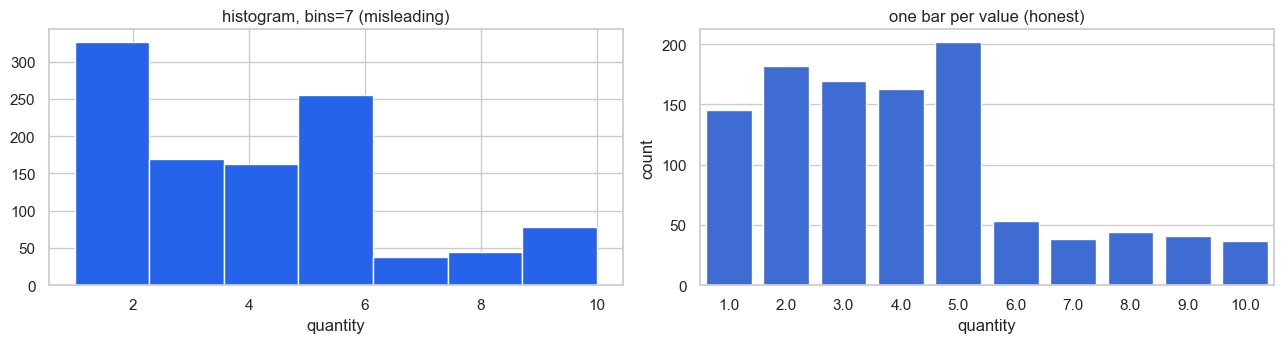

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].hist(orders["quantity"], bins=7, color="#2563eb", edgecolor="white")
axes[0].set(title="histogram, bins=7 (misleading)", xlabel="quantity")
sns.countplot(data=orders, x="quantity", color="#2563eb", ax=axes[1])
axes[1].set(title="one bar per value (honest)", xlabel="quantity")
plt.tight_layout()
plt.show()

In [26]:
orders["quantity"].value_counts().sort_index()

quantity
1.0     145
2.0     182
3.0     169
4.0     163
5.0     202
6.0      53
7.0      38
8.0      44
9.0      41
10.0     37
Name: count, dtype: int64

With 7 bins over the range 1 to 10, some bars hold two quantities and some hold one, so the bar heights aren't comparable.
For a column with a few whole-number values, count each value: `value_counts()` + a bar chart (`sns.countplot`, `px.histogram` with one bin per value).

---
# 🧰 Cheat Sheet

| Question | Chart | Matplotlib | Seaborn | Plotly |
|---|---|---|---|---|
| Shape of one numeric column | Histogram | `ax.hist` | `sns.histplot` | `px.histogram` |
| Huge range (×10, ×100) | Log axis | `ax.set_xscale("log")` | `log_scale=True` | `log_x=True` |
| Compare 2–4 group shapes | KDE | — | `sns.kdeplot(hue=...)` | — |
| Compare many groups, outliers | Box plot | `ax.boxplot` | `sns.boxplot` | `px.box` |
| Shape per group | Violin | `ax.violinplot` | `sns.violinplot` | `px.violin` |
| Every single point | Strip | — | `sns.stripplot` | `px.strip` |
| Share below a threshold | ECDF | — | `sns.ecdfplot` | `px.ecdf` |
| Few whole-number values | Bar of counts | `ax.bar` | `sns.countplot` | `px.histogram` |

**Before you trust a distribution chart:** try a few bin counts, check whether a log axis is needed, and look at the edges for values that can't exist.

**Next lesson:** Comparison & Ranking — bar charts done right.